# 📊 Étape 5 — Évaluation Rigoureuse (Le Triptyque de Métriques) & Inférence Locale GGUF 💻 *(Exécution Locale)*

**Environnement** : Ce notebook tourne **100% en local sur ton PC (CPU)**.

**Objectif pédagogique** : Mesurer scientifiquement les progrès de ton modèle avec nos **3 métriques complémentaires** sur ton PC :
1. **La Perplexité** ($\text{PPL} = \exp(\text{Loss})$)
2. **Le *Camfranglais Adherence Score*** (comparaison de la distribution du score $S$ du modèle face aux vraies réponses humaines via `../config/lexicon.json`)
3. **La Pertinence Sémantique** (Similarité Cosinus des embeddings multilingues sur CPU)
4. **L'Inférence Locale** avec le fichier GGUF exporté à l'Étape 4.

In [1]:
import math
import re
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from typing import List, Dict
from dotenv import load_dotenv

PROJECT_ROOT = Path("..").resolve()
load_dotenv(PROJECT_ROOT / ".env")

with open(PROJECT_ROOT / "config" / "lexicon.json", "r", encoding="utf-8") as f:
    LEXICON = json.load(f)

print(f"✅ Environnement local prêt. Lexique chargé depuis {PROJECT_ROOT / 'config' / 'lexicon.json'}")

✅ Environnement local prêt. Lexique chargé depuis C:\Users\arist\Documents\Mes Projets IA\CamfranglaisLLM\CamfranglaisLLM\config\lexicon.json


---
## 1. Métrique 1 : La Perplexité ($\text{PPL} = \exp(\text{Loss})$) (`TODO 1`)

Complète le **`TODO 1`** pour convertir la *Cross-Entropy Loss* en **Perplexité** :
$$\text{PPL} = \exp(\text{eval\_loss})$$

In [2]:
# === EXERCICE GUIDÉ : TODO 1 ===
def compute_perplexity_from_loss(eval_loss: float) -> float:
    """
    Calcule la perplexité PPL = exp(eval_loss).
    Astuce : utilise `math.exp(eval_loss)`.
    """
    # TODO 1 : Retourner l'exponentielle de `eval_loss`
    
    # --- TON CODE ICI ---
    return math.exp(eval_loss)
    # --------------------

In [3]:
# 🧪 Cellule de validation du TODO 1
ppl_before = compute_perplexity_from_loss(3.3524)
ppl_after = compute_perplexity_from_loss(0.5330)
print(f"Perplexité initiale (Loss=3.35) : {ppl_before:.2f}")
print(f"Perplexité finale   (Loss=0.53) : {ppl_after:.2f}")
assert abs(ppl_before - math.exp(3.3524)) < 1e-3
assert ppl_after < ppl_before
print("🎉 TODO 1 validé !")

Perplexité initiale (Loss=3.35) : 28.57
Perplexité finale   (Loss=0.53) : 1.70
🎉 TODO 1 validé !


---
## 2. Métrique 2 : Le *Camfranglais Adherence Score* (`TODO 2`)

Complète le **`TODO 2`** pour comparer la moyenne $\mu_{\text{modèle}}$ et l'écart-type $\sigma_{\text{modèle}}$ du score $S$ sur les réponses générées par le modèle avec $(\mu_{\text{humain}}, \sigma_{\text{humain}})$ des vraies réponses humaines.

In [4]:
# === EXERCICE GUIDÉ : TODO 2 ===
def evaluate_camfranglais_adherence(
    model_scores: List[float],
    human_scores: List[float]
) -> Dict[str, float]:
    """
    Compare la distribution des scores S des réponses du modèle avec celle des humains.
    Retourne un dictionnaire contenant :
      - 'model_mean': moyenne de model_scores
      - 'model_std': écart-type de model_scores
      - 'human_mean': moyenne de human_scores
      - 'human_std': écart-type de human_scores
      - 'mean_abs_gap': |model_mean - human_mean| (plus c'est proche de 0, plus le dosage est naturel !)
      - 'active_camfranglais_rate': proportion des réponses du modèle ayant un score S > 0.0
    """
    m_arr = np.array(model_scores, dtype=float)
    h_arr = np.array(human_scores, dtype=float)

    # TODO 2 : Calculer les métriques avec `np.mean`, `np.std`, `abs(...)` et `np.mean(m_arr > 0.0)`
    
    # --- TON CODE ICI ---
    model_mean =np.mean(m_arr)
    model_std = np.std(m_arr)
    human_mean = np.mean(h_arr)
    human_std = np.std(h_arr)
    mean_abs_gap = abs(model_mean - human_mean)
    active_camfranglais_rate = np.mean(m_arr > 0.0)
    
    
    return {
        'model_mean': model_mean,
        'model_std': model_std,
        'human_mean': human_mean,
        'human_std': human_std,
        'mean_abs_gap': mean_abs_gap,
        'active_camfranglais_rate': active_camfranglais_rate
    }
    # --------------------

In [5]:
# 🧪 Cellule de validation du TODO 2
mock_human_s = [0.22, 0.30, 0.18, 0.25, 0.28]
mock_model_s = [0.20, 0.27, 0.19, 0.24, 0.25]

adherence_report = evaluate_camfranglais_adherence(mock_model_s, mock_human_s)
print("Rapport d'adhérence stylistique :", json.dumps(adherence_report, indent=2))

assert "mean_abs_gap" in adherence_report and adherence_report["mean_abs_gap"] < 0.05
assert adherence_report["active_camfranglais_rate"] == 1.0
print("🎉 TODO 2 validé !")

Rapport d'adhérence stylistique : {
  "model_mean": 0.22999999999999998,
  "model_std": 0.030331501776206204,
  "human_mean": 0.246,
  "human_std": 0.04270831300812525,
  "mean_abs_gap": 0.016000000000000014,
  "active_camfranglais_rate": 1.0
}
🎉 TODO 2 validé !


---
## 3. Métrique 3 : Pertinence Sémantique sur CPU par Similarité Cosinus (`TODO 3`)

Le modèle `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2` tourne très rapidement sur le CPU de ton PC pour comparer chaque réponse générée $\vec{u}_i$ avec la réponse humaine de référence $\vec{v}_i$.

In [9]:
# === EXERCICE GUIDÉ : TODO 3 ===
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", device="cpu")

def compute_semantic_similarity(
    generated_responses: List[str],
    reference_responses: List[str]
) -> Dict[str, float]:
    """
    Encode les réponses générées et les réponses de référence avec `embedder.encode(..., normalize_embeddings=True)`
    et calcule la similarité cosinus moyenne paire par paire.
    """
    # TODO 3 : Encoder les deux listes et retourner `{"mean_cosine_similarity": ..., "min_similarity": ..., "max_similarity": ...}`
    
    # --- TON CODE ICI ---
    if len(generated_responses) != len(reference_responses):
        raise ValueError("Les deux listes doivent avoir la même longueur.")
    
    generated_embeddings = embedder.encode(generated_responses, normalize_embeddings = True)
    reference_embeddings = embedder.encode(reference_responses, normalize_embeddings = True)
    
    cosine_similarties = np.sum(generated_embeddings * reference_embeddings, axis=1)
    
    return {
        "mean_cosine_similarity": np.mean(cosine_similarties),
        "min_similarity": np.min(cosine_similarties),
        "max_similarity": np.max(cosine_similarties)
    }
    # --------------------

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2078.43it/s]


In [10]:
# 🧪 Cellule de validation du TODO 3
gen_samples = [
    "Gars, Eneo a encore coupé le courant, on va dormir dans le noir ce soir.",
    "Je te donne 2000 francs demain matin frère."
]
ref_samples = [
    "C'est la magie, Eneo a coupé l'électricité, il fait tout noir dans la maison.",
    "Pas de souci bro, je te passe les 2 kollo demain."
]

sem_stats = compute_semantic_similarity(gen_samples, ref_samples)
print("Pertinence sémantique :", sem_stats)
assert sem_stats["mean_cosine_similarity"] > 0.55
print("🎉 TODO 3 validé !")

Pertinence sémantique : {'mean_cosine_similarity': np.float32(0.6776401), 'min_similarity': np.float32(0.65072596), 'max_similarity': np.float32(0.70455426)}
🎉 TODO 3 validé !


---
## 4. Visualisation Comparative & Inférence Locale GGUF sur ton PC (`TODO 4`)

Complète le **`TODO 4`** pour tracer côte à côte la distribution des scores $S$ du modèle face aux humains avec `matplotlib` !

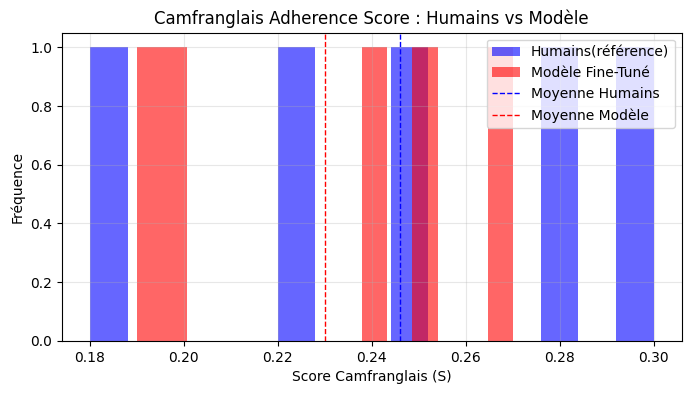

In [13]:
# === EXERCICE GUIDÉ : TODO 4 ===
def plot_adherence_distributions(model_scores: List[float], human_scores: List[float]):
    """
    Trace l'histogramme comparatif de la densité de Camfranglais (Score S)
    entre les vraies réponses humaines et les réponses générées par le modèle.
    """
    plt.figure(figsize=(8, 4))
    # TODO 4 : Tracer deux histogrammes (`plt.hist`) avec `alpha=0.6`, `bins=15`
    # pour `human_scores` (label='Humains (Référence)') et `model_scores` (label='Modèle Fine-Tuné'),
    # plus les lignes verticales des moyennes (`plt.axvline`).
    
    # --- TON CODE ICI ---
    plt.hist(human_scores, bins=15, alpha=0.6, label='Humains(référence)', color='blue')
    plt.hist(model_scores, bins=15, alpha=0.6, label='Modèle Fine-Tuné', color='red')   
    plt.axvline(np.mean(human_scores), color='blue', linestyle='dashed', linewidth=1, label='Moyenne Humains')
    plt.axvline(np.mean(model_scores), color='red', linestyle='dashed', linewidth=1, label='Moyenne Modèle')
    # --------------------
    plt.xlabel("Score Camfranglais (S)")
    plt.ylabel("Fréquence")
    plt.title("Camfranglais Adherence Score : Humains vs Modèle")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

# Test d'affichage :
plot_adherence_distributions(mock_model_s, mock_human_s)